# Einstein Cross — full RFS imaging POVM reconstruction

**Important memory warning.** For `d=15`, the construction `rho2_turb = np.kron(rho1_turb, rho1_turb)` produces a dense `50,625 × 50,625` complex128 matrix (about **38.2 GiB** for that array alone, with additional peak memory for temporaries). Run only with sufficient RAM.

Requires `numpy`, `matplotlib` and `imaging_povm.py` in the same directory. 

In [2]:
import numpy as np
from imaging_povm import (
    phi_from_P_2d, P_from_phi, analytic_chis_from_phi,
    kolmogorov_phase_screen, rho1_from_phi_with_phase_screen, rho2_from_rho1,
    block_swap_probs_plain_global_2d_fast,
    block_swap_probs_rotated_X_global_2d_fast,
    block_swap_probs_rotated_Y_global_2d_fast,
    speckle_image_from_phase_and_P,
    reconstruct_phi_from_chis_2d_full,
    enforce_hermitian_phi_with_amplitudes,
    anchor_povm_offdiagonal_2d,
    fix_ac_sign_with_anchor_and_brightness_prior,
    gs_P_from_chi_plain_2d,
    orient_P_using_phi_reference_2d,
    plot_P_true_est_speckle,
    plot_P_true_est_speckle_2,
)

In [4]:
EINSTEIN_CROSS = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 10, 65, 121, 83, 25, 9, 7, 8, 7, 10, 16, 23, 14, 0],
    [0, 29, 131, 238, 181, 55, 14, 14, 14, 18, 34, 95, 132, 60, 0],
    [0, 44, 140, 239, 198, 88, 45, 45, 48, 54, 81, 195, 245, 107, 0],
    [0, 31, 76, 127, 124, 102, 93, 102, 110, 110, 122, 186, 198, 89, 0],
    [0, 11, 25, 49, 77, 107, 135, 161, 173, 164, 143, 126, 97, 47, 0],
    [0, 5, 15, 42, 78, 117, 159, 190, 202, 190, 147, 92, 48, 24, 0],
    [0, 17, 39, 73, 98, 124, 165, 193, 201, 186, 135, 70, 27, 12, 0],
    [0, 41, 115, 166, 127, 111, 146, 177, 181, 163, 114, 57, 18, 8, 0],
    [0, 59, 160, 214, 136, 93, 109, 130, 131, 110, 83, 53, 18, 8, 0],
    [0, 48, 106, 135, 100, 70, 61, 69, 82, 87, 83, 57, 25, 12, 0],
    [0, 22, 40, 52, 49, 36, 22, 28, 63, 148, 175, 95, 29, 10, 0],
    [0, 5, 11, 16, 14, 10, 7, 11, 45, 140, 188, 109, 27, 6, 0],
    [0, 4, 6, 6, 5, 6, 8, 9, 22, 52, 76, 57, 25, 11, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)

d = 15
P_true = EINSTEIN_CROSS.astype(float)
P_true /= P_true.sum()
r0_pix = (d // 2) / 6
rng = np.random.default_rng(0)
n_gs_iters = 1000
n_gs_restarts = 10

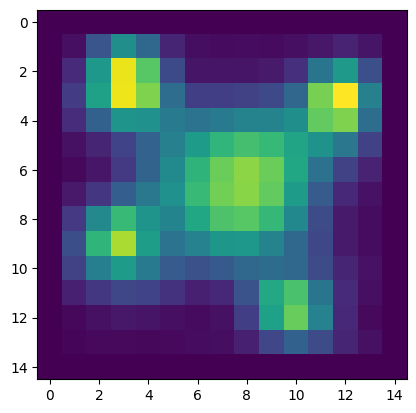

In [10]:
import matplotlib.pyplot as plt
plt.imshow(P_true)

## 1. Fourier source, a single atmospheric screen, and the two-copy state

In [13]:
phi_true = phi_from_P_2d(P_true)
chi_plain_ana, chiX_x_ana, chiY_x_ana, chiX_y_ana, chiY_y_ana = analytic_chis_from_phi(phi_true)

phase_screen = kolmogorov_phase_screen(d, r0_pix, rng=rng)
rho1_turb = rho1_from_phi_with_phase_screen(phi_true, phase_screen)

# Dense rho2 = rho1 ⊗ rho1; memory-intensive for d=15 (~38.2 GiB).
rho2_turb = rho2_from_rho1(rho1_turb)

## 2. RFS measurement: plain and X/Y-rotated block-SWAP outcomes

Compute each `(m, ±)` probability from the same **turbulent** two-photon density matrix. Differences `p_+ − p_-` are the measured contrasts `χ`. The DC power is fixed analytically because the zero-shift plain exchange block is not a generic measurement outcome.

In [15]:
p_plus_plain, p_minus_plain = block_swap_probs_plain_global_2d_fast(rho2_turb, d)
chi_plain_num = p_plus_plain - p_minus_plain
chi_plain_num[0, 0] = 1.0 / (d*d)  # phi_00 = 1

p_plus_Xx, p_minus_Xx = block_swap_probs_rotated_X_global_2d_fast(rho2_turb, d, direction="x")
p_plus_Xy, p_minus_Xy = block_swap_probs_rotated_X_global_2d_fast(rho2_turb, d, direction="y")
chiX_x_num = p_plus_Xx - p_minus_Xx
chiX_y_num = p_plus_Xy - p_minus_Xy

p_plus_Yx, p_minus_Yx = block_swap_probs_rotated_Y_global_2d_fast(rho2_turb, d, direction="x")
p_plus_Yy, p_minus_Yy = block_swap_probs_rotated_Y_global_2d_fast(rho2_turb, d, direction="y")
chiY_x_num = p_plus_Yx - p_minus_Yx
chiY_y_num = p_plus_Yy - p_minus_Yy

## 3. Coherence chaining, Hermitian amplitudes


In [17]:
phi0 = reconstruct_phi_from_chis_2d_full(
    chi_plain_num, chiX_x_num, chiY_x_num, chiX_y_num, chiY_y_num
)
if abs(phi0[0, 0]) > 1e-12:
    phi0 *= np.exp(-1j * np.angle(phi0[0, 0]))

phi2_ac = enforce_hermitian_phi_with_amplitudes(phi0, chi_plain_num)
anchors = anchor_povm_offdiagonal_2d(rho1_turb, d)
phi2 = fix_ac_sign_with_anchor_and_brightness_prior(
    phi2_ac, chi_plain_num,
    P_from_phi_func=P_from_phi,
    phi10_anchor=anchors["phi10_anchor"],
    phi01_anchor=anchors["phi01_anchor"],
    k_bright=10,
    prior="dark",
)
P_ref = P_from_phi(phi2)

valid_x(d-1,0) = False  valid_y(0,d-1) = False  valid(0,0) = False False


## 4. Amplitude-only Gerchberg–Saxton and orientation

In [19]:
P_gs = gs_P_from_chi_plain_2d(
    chi_plain_num,
    n_iters=n_gs_iters,
    n_restarts=n_gs_restarts,
    rng=rng,
    phi_init=phi2,
)
P_est, label, conf, P_ref = orient_P_using_phi_reference_2d(
    P_gs, P_ref,
    chi_plain_num, chiX_x_num, chiY_x_num, chiX_y_num, chiY_y_num,
)
I_speckle = speckle_image_from_phase_and_P(P_true, phase_screen)

print("L2(P_ref, P_true) =", np.sum((P_ref - P_true)**2))
print("L2(P_est, P_true) =", np.sum((P_est - P_true)**2))
print("L2(P_classical speckle, P_true) =", np.sum((I_speckle - P_true)**2))
print("max |phi2 - phi_true| =", np.max(np.abs(phi2 - phi_true)))

L2(P_ref, P_true) = 0.0003605763076977112
L2(P_est, P_true) = 0.00035094457582008384
L2(P_classical speckle, P_true) = 0.0033082042392648175
max |phi2 - phi_true| = 0.09739548281817283


## 5. Paper image

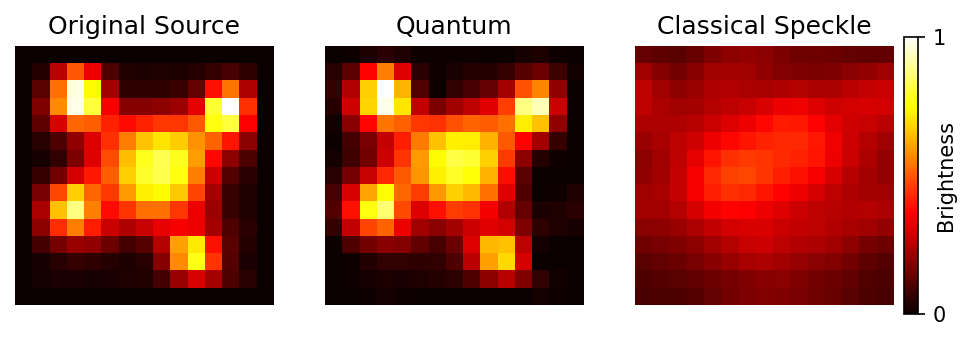

In [21]:
plot_P_true_est_speckle_2(
    P_true, P_ref, I_speckle,
    titles=("Original Source", "Quantum", "Classical Speckle"),
)

SHOW_FOUR_PANELS = False
if SHOW_FOUR_PANELS:
    plot_P_true_est_speckle(
        P_true, P_ref, P_est, I_speckle,
        titles=("Original Source", "Quantum 1", "Quantum 2", "Classical Speckle"),
    )